Analyse des données des Coupes du monde :

Objectif

Analyser les performances des équipes lors des Coupes du monde de football de 1930 à 2022, puis étudier les résultats des pays organisateurs.


In [1]:
import pandas as pd

df_fifa = pd.read_csv("../outputs/fifa_prepared.csv")

In [2]:
df_fifa.shape

(489, 13)

Nous commençons par une première analyse descriptive, pour comprendre les données avant de poser des questions plus précises.

In [3]:
df_fifa.describe()

,Position,Games Played,Win,Draw,Loss,Goals For,Goals Against,Goal Difference,Points,Year
count,489.000000,489.000000,489.000000,489.000000,489.000000,489.000000,489.000000,489.000000,489.000000,489.000000
mean,12.838446,3.938650,1.541922,0.854806,1.541922,5.560327,5.560327,0.000000,4.730061,1987.186094
std,8.306900,1.469749,1.550641,0.864476,0.778016,4.527346,2.748498,4.733037,4.151429,26.098178
min,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-16.000000,0.000000,1930.000000
25%,6.000000,3.000000,0.000000,0.000000,1.000000,2.000000,4.000000,-3.000000,2.000000,1970.000000
50%,12.000000,3.000000,1.000000,1.000000,2.000000,4.000000,5.000000,-1.000000,4.000000,1994.000000
75%,18.000000,5.000000,2.000000,1.000000,2.000000,8.000000,7.000000,2.000000,7.000000,2010.000000
max,32.000000,7.000000,7.000000,4.000000,3.000000,27.000000,16.000000,17.000000,21.000000,2022.000000


Description des statistiques descriptives :

Le jeu de données comprend 489 observations pour chacune des colonnes numériques.

Le nombre de matchs joués (Games Played) varie de 1 à 32, avec une moyenne de 12,84 et une médiane de 12.

Le nombre de victoires (Win) varie de 0 à 7, avec une moyenne de 3,94. Le nombre de matchs nuls (Draw) varie de 0 à 7, et celui des défaites (Loss) de 0 à 4.

Le nombre de buts marqués (Goals For) varie de 0 à 27, avec une moyenne de 5,56. Le nombre de buts encaissés (Goals Against) varie également de 0 à 27, avec une moyenne de 5,56.

La différence de buts (Goal Difference) varie de -16 à 16. Les points (Points) varient de -16 à 17.

Enfin, les années représentées dans le jeu de données vont de 1930 à 2022.

Question : quelles équipes ont participé le plus souvent aux Coupes du monde ?

In [4]:
df_fifa["Team_Harmonized"].value_counts()

Team_Harmonized
Brazil                    22
Germany                   20
Italy                     18
Argentina                 18
Mexico                    17
                          ..
Slovakia                   1
Bosnia and Herzegovina     1
Iceland                    1
Panama                     1
Qatar                      1
Name: count, Length: 80, dtype: int64

Le jeu de données compte 80 valeurs distinctes dans Team_Harmonized.

Le Brésil apparaît le plus souvent, avec 22 participations.

L'Allemagne apparaît 20 fois, puis l'Italie et l'Argentine 18 fois chacune.

À l'inverse, plusieurs équipes n'apparaissent qu'une seule fois, comme la Slovaquie, l'Islande, le Panama et le Qatar.

En rappelant que le comptage dépend de notre harmonisation des noms historiques. 

In [5]:
df_fifa["Team_Harmonized"].value_counts().head(10)

Team_Harmonized
Brazil       22
Germany      20
Italy        18
Argentina    18
Mexico       17
France       16
England      16
Spain        16
Belgium      14
Uruguay      14
Name: count, dtype: int64

Question : quelles équipes ont marqué le plus de buts au total sur toutes les éditions ?

In [6]:
df_fifa.groupby("Team_Harmonized")["Goals For"].sum().sort_values(ascending=False).head(10)

Team_Harmonized
Brazil         237
Germany        232
Argentina      152
France         136
Italy          127
Spain          108
England        104
Netherlands     96
Uruguay         89
Hungary         87
Name: Goals For, dtype: int64

Le Brésil arrive en tête avec 237 buts, suivi de l'Allemagne avec 232. L'Argentine occupe la troisième place avec 152 buts. Ce classement ne tient en revanche pas compte du nombre de matchs joués.

Calculer les buts marqués par match

In [7]:
stats_equipes = df_fifa.groupby("Team_Harmonized")[["Goals For", "Games Played"]].sum()

stats_equipes

,Goals For,Games Played
Team_Harmonized,,
Algeria,13,13
Angola,1,3
Argentina,152,88
Australia,17,20
Austria,43,29
...,...,...
Ukraine,5,5
United Arab Emirates,2,3
United States,40,37


In [8]:
stats_equipes["Goals For"] / stats_equipes["Games Played"]

Team_Harmonized
Algeria                 1.000000
Angola                  0.333333
Argentina               1.727273
Australia               0.850000
Austria                 1.482759
                          ...   
Ukraine                 1.000000
United Arab Emirates    0.666667
United States           1.081081
Uruguay                 1.508475
Wales                   0.625000
Length: 80, dtype: float64

In [9]:
stats_equipes["Goals Per Match"] = (
    stats_equipes["Goals For"] / stats_equipes["Games Played"]
)

stats_equipes

,Goals For,Games Played,Goals Per Match
Team_Harmonized,,,
Algeria,13,13,1.000000
Angola,1,3,0.333333
Argentina,152,88,1.727273
Australia,17,20,0.850000
Austria,43,29,1.482759
...,...,...,...
Ukraine,5,5,1.000000
United Arab Emirates,2,3,0.666667
United States,40,37,1.081081


In [10]:
stats_equipes.sort_values(
    by="Goals Per Match",
    ascending=False
).head(10)

,Goals For,Games Played,Goals Per Match
Team_Harmonized,,,
Hungary,87,32,2.718750
Brazil,237,114,2.078947
Germany,232,112,2.071429
Turkey,20,10,2.000000
France,136,73,1.863014
Netherlands,96,55,1.745455
Portugal,61,35,1.742857
Argentina,152,88,1.727273
Russia,77,45,1.711111


In [11]:
stats_equipes["Goals Per Match"] = stats_equipes["Goals Per Match"].round(2)

stats_equipes.sort_values(
    by="Goals Per Match",
    ascending=False
).head(10)

,Goals For,Games Played,Goals Per Match
Team_Harmonized,,,
Hungary,87,32,2.72
Brazil,237,114,2.08
Germany,232,112,2.07
Turkey,20,10,2.00
France,136,73,1.86
Netherlands,96,55,1.75
Portugal,61,35,1.74
Argentina,152,88,1.73
Russia,77,45,1.71


Comparer les pays hôtes aux autres équipes


Combien de victoires les équipes hôtes et les équipes non hôtes ont-elles cumulées ?

In [12]:
df_fifa.groupby("Host")["Win"].sum()

Host
False    681
True      73
Name: Win, dtype: int64

681 victoires pour les équipes non organisatrices.
73 victoires pour les équipes organisatrices.

On ne peut toutefois pas conclure que les pays organisateurs gagnent moins souvent à partir de ces seuls totaux. Il y a beaucoup plus de lignes pour les équipes non organisatrices (466 contre 23).

Comparaison des victoires au nombre de matchs joués
On va obtenir, pour chaque groupe, le nombre total de victoires et le nombre total de matchs joués. Cela nous permettra de calculer une proportion de victoires par match joué, plus pertinente que de comparer les totaux seuls.

In [13]:
df_fifa.groupby("Host")[["Win", "Games Played"]].sum()

,Win,Games Played
Host,,
False,681,1806
True,73,120


Cependant à présent nous allons nous intéresser à qui sont les pays hôtes et si le fait d'avoir accueilli une coupe du monde leur permet d'avoir un résultat différent que lorsqu'ils n'organisent pas.

In [14]:
df_fifa[["Year", "Team", "Team_Harmonized", "Position", "Host"]].head(10)

,Year,Team,Team_Harmonized,Position,Host
0,1930,Uruguay,Uruguay,1,True
1,1930,Argentina,Argentina,2,False
2,1930,United States,United States,3,False
3,1930,Yugoslavia,Serbia,4,False
4,1930,Chile,Chile,5,False
5,1930,Brazil,Brazil,6,False
6,1930,France,France,7,False
7,1930,Romania,Romania,8,False
8,1930,Paraguay,Paraguay,9,False
9,1930,Peru,Peru,10,False


In [15]:
pays_hotes = df_fifa.loc[df_fifa["Host"], "Team_Harmonized"].unique()

pays_hotes

array(['Uruguay', 'Italy', 'France', 'Brazil', 'Switzerland', 'Sweden',
       'Chile', 'England', 'Mexico', 'Germany', 'Argentina', 'Spain',
       'United States', 'South Korea', 'Japan', 'South Africa', 'Russia',
       'Qatar'], dtype=object)

On veut maintenant conserver toutes les lignes correspondant aux 18 pays, y compris lorsqu'ils n'organisent pas la compétition.

In [16]:
df_pays_hotes = df_fifa[
    df_fifa["Team_Harmonized"].isin(pays_hotes)
]

df_pays_hotes.shape

(234, 13)

In [17]:
df_pays_hotes["Host"].value_counts()

Host
False    211
True      23
Name: count, dtype: int64

In [18]:
comparaison_host = df_pays_hotes.groupby("Host").agg(
    Victoires=("Win", "sum"),
    Matchs_joues=("Games Played", "sum"),
    Position_moyenne=("Position", "mean")
)

comparaison_host

,Victoires,Matchs_joues,Position_moyenne
Host,,,
False,396,890,10.317536
True,73,120,6.391304


première observation, les pays hôtes ont une position finale moyenne meilleure que lorsqu'ils participent sans être hôtes, dans les données que nous avons sélectionnées.

In [19]:
comparaison_host["Victoires_par_match"] = (
    comparaison_host["Victoires"] / comparaison_host["Matchs_joues"]
)

comparaison_host

,Victoires,Matchs_joues,Position_moyenne,Victoires_par_match
Host,,,,
False,396,890,10.317536,0.444944
True,73,120,6.391304,0.608333


In [20]:
df_pays_hotes.groupby("Host")["Position"].count()

Host
False    211
True      23
Name: Position, dtype: int64

In [21]:
comparaison_host.round(2)

,Victoires,Matchs_joues,Position_moyenne,Victoires_par_match
Host,,,,
False,396,890,10.32,0.44
True,73,120,6.39,0.61


Analyse comparative des pays hôtes et non hôtes :

Objectif :

L'objectif est d'observer si les pays organisateurs obtiennent de meilleurs résultats lorsqu'ils accueillent la Coupe du monde que lorsqu'ils y participent sans être pays hôte.

L'analyse porte sur les 18 pays ayant accueilli au moins une édition, en comparant leurs participations à domicile et hors domicile.

Résultats :

Les résultats obtenus sont les suivants :

La proportion de victoires par match joué est plus élevée lorsque les pays organisent la compétition : 61 % contre 44 % lorsqu'ils ne sont pas hôtes.

La position finale moyenne est également meilleure lors des éditions organisées par ces pays. Elle est de 6,39 à domicile contre 10,32 hors domicile. Une position plus faible correspondant à un meilleur classement, cette observation va dans le sens de l'hypothèse d'un avantage du pays organisateur.

Limites de l'analyse :

Des effectifs différents : l'analyse repose sur 23 participations en tant que pays hôte contre 211 participations hors domicile. Le nombre de participations à domicile est donc relativement faible.

Des périodes historiques différentes : les données couvrent les éditions de 1930 à 2022. Le niveau des équipes, les formats de compétition et le nombre de matchs joués ont évolué au fil du temps.

Des performances variables selon les pays : les résultats dépendent notamment du niveau sportif de chaque équipe et de son évolution d'une édition à l'autre.

Une harmonisation des noms : certaines équipes historiques ont été regroupées sous un même nom de référence. Cette convention facilite les comparaisons, mais peut influencer les résultats.

Une relation qui ne démontre pas une causalité : les données montrent une différence de résultats entre les deux situations, mais ne permettent pas d'affirmer que l'organisation de la compétition est à elle seule responsable de cette différence.

Conclusion :

Dans les données étudiées, les pays hôtes présentent une proportion de victoires plus élevée et une meilleure position finale moyenne que lors de leurs participations hors domicile.

Ces observations sont compatibles avec l'hypothèse d'un avantage du pays organisateur. Elles doivent toutefois être interprétées avec prudence, compte tenu des différences d'effectifs, des évolutions historiques et des performances propres à chaque équipe.

On va comparer à présent, pour chacun des pays hôtes, ses résultats lorsqu’il organisait la compétition à ses résultats lors de ses autres participations. Nous allons exclure le Qatar de cette comparaison, puisqu'il est le seul pays hôte à n'avoir participé qu'à la coupe du monde qu'il organisait.

In [22]:
df_comparaison_pays = df_pays_hotes[
    df_pays_hotes["Team_Harmonized"] != "Qatar"
]

In [23]:
comparaison_par_pays = df_comparaison_pays.groupby(
    ["Team_Harmonized", "Host"]
).size().unstack(fill_value=0)

comparaison_par_pays

Host,False,True
Team_Harmonized,,
Argentina,17,1
Brazil,20,2
Chile,8,1
England,15,1
France,14,2
Germany,18,2
Italy,16,2
Japan,6,1
Mexico,15,2


Nous allons calculer pour chaque pays, sa position moyenne lorsqu’il est hôte et lorsqu’il ne l’est pas.

In [24]:
comparaison_positions = df_comparaison_pays.groupby(
    ["Team_Harmonized", "Host"]
)["Position"].mean().unstack()

comparaison_positions

Host,False,True
Team_Harmonized,,
Argentina,7.294118,1.0
Brazil,4.900000,3.0
Chile,11.875000,3.0
England,8.666667,1.0
France,9.357143,4.5
Germany,5.277778,2.0
Italy,8.500000,2.0
Japan,20.333333,9.0
Mexico,13.400000,6.0


On observe que la position moyenne s’améliore à domicile pour la plupart des pays.
Uruguay : position moyenne de 10,85 hors domicile contre 1 à domicile (vainqueur lors de sa seule réception en 1930)
Allemagne : 5,28 contre 2.
Corée du Sud : 20,8 contre 4 (demi finaliste lors de sa seule réception en 2002).

En revanche certains pays dérogent à cette observation, comme par exemple l'Espagne : 9,8 hors domicile contre 12 à domicile (éliminée lors du 2e tour lors de sa seule réception en 1982, et vainqueur à l'extérieur en 2010). Pour l'Afrique du Sud et les USA, l'organisation de la compétition n'a eu que très peu d'impact sur leur position moyenne.

In [25]:
comparaison_positions["Ecart_position"] = (
    comparaison_positions[False] - comparaison_positions[True]
)

comparaison_positions.sort_values(
    "Ecart_position", ascending=False
)

Host,False,True,Ecart_position
Team_Harmonized,,,
South Korea,20.800000,4.0,16.800000
Japan,20.333333,9.0,11.333333
Uruguay,10.846154,1.0,9.846154
Chile,11.875000,3.0,8.875000
England,8.666667,1.0,7.666667
Mexico,13.400000,6.0,7.400000
Sweden,9.090909,2.0,7.090909
Switzerland,12.000000,5.0,7.000000
Italy,8.500000,2.0,6.500000


La comparaison des 17 pays ayant participé à au moins une Coupe du monde à domicile et à une autre hors domicile montre que 16 pays sur 17 présentent une position moyenne plus favorable lorsqu'ils organisent la compétition. L'Espagne constitue l'exception, avec une position moyenne de 12 à domicile contre 9,8 hors domicile.

Les écarts les plus importants sont observés pour la Corée du Sud (+16,8), le Japon (+11,33) et l'Uruguay (+9,85). Ces écarts doivent toutefois être interprétés avec prudence. Plusieurs pays n'ont accueilli qu'une seule édition, et les résultats dépendent aussi du niveau sportif de chaque sélection, de l'époque et du format de la compétition.

Cette analyse suggère une association entre le statut de pays hôte et de meilleurs résultats, mais elle ne suffit pas à démontrer que l'organisation de la compétition est la seule cause de cette amélioration.

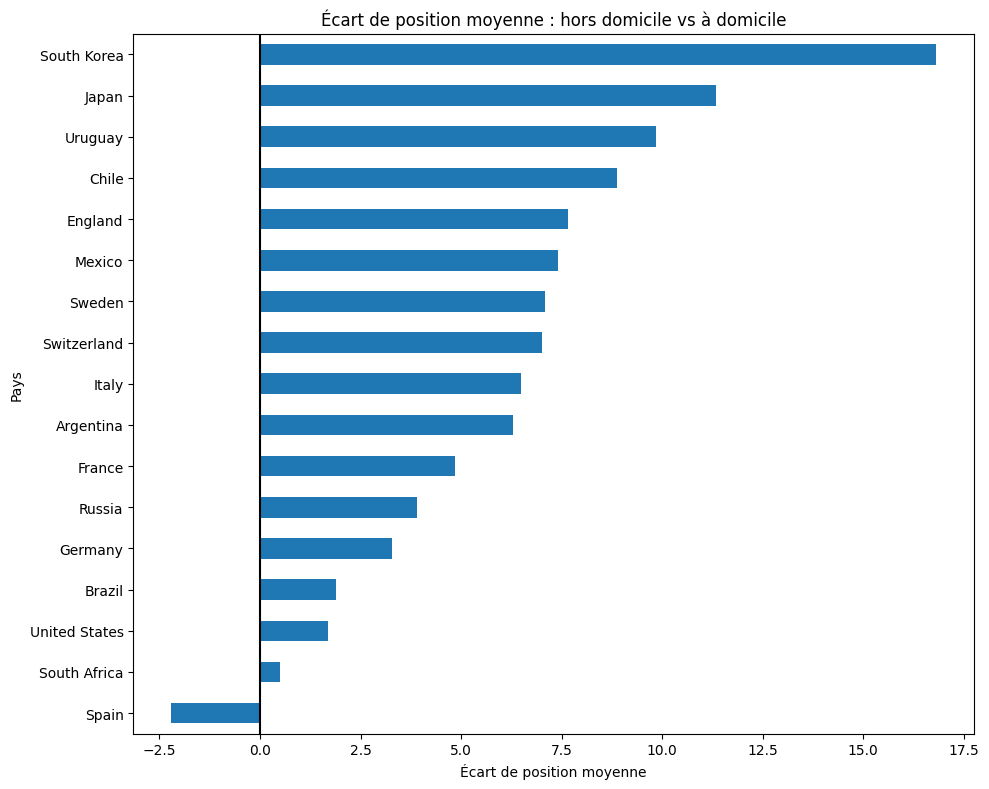

In [26]:
import matplotlib.pyplot as plt

comparaison_positions["Ecart_position"].sort_values().plot.barh(
    figsize=(10, 8),
    title="Écart de position moyenne : hors domicile vs à domicile"
)

plt.xlabel("Écart de position moyenne")
plt.ylabel("Pays")
plt.axvline(x=0, color="black")
plt.tight_layout()
plt.show()

In [27]:
bilan_editions = df_fifa.groupby("Year")[["Games Played", "Goals For"]].sum()

bilan_editions

,Games Played,Goals For
Year,,
1930,36,70
1934,32,69
1938,36,84
1950,44,88
1954,52,140
1958,70,126
1962,64,89
1966,64,89
1970,64,95


Attention, la colonne Games Played compte chaque match deux fois (1 fois pour chaque équipe). Pour obtenir le nombre réel de matchs par édition, on divise par 2.

In [28]:
bilan_editions["Nombre de matchs"] = bilan_editions["Games Played"] / 2

bilan_editions[["Nombre de matchs", "Goals For"]]

,Nombre de matchs,Goals For
Year,,
1930,18.0,70
1934,16.0,69
1938,18.0,84
1950,22.0,88
1954,26.0,140
1958,35.0,126
1962,32.0,89
1966,32.0,89
1970,32.0,95


Calculer la moyenne de buts par match permet de comparer les éditions malgré les différences de format.

In [29]:
bilan_editions["Buts par match"] = (
    bilan_editions["Goals For"] / bilan_editions["Nombre de matchs"]
)

bilan_editions[["Nombre de matchs", "Goals For", "Buts par match"]].round(2)

,Nombre de matchs,Goals For,Buts par match
Year,,,
1930,18.0,70,3.89
1934,16.0,69,4.31
1938,18.0,84,4.67
1950,22.0,88,4.00
1954,26.0,140,5.38
1958,35.0,126,3.60
1962,32.0,89,2.78
1966,32.0,89,2.78
1970,32.0,95,2.97


Le nombre moyen de buts par match évolue dans le temps. Il atteint son niveau le plus élevé en 1954, avec 5,38 buts par match, et son niveau le plus faible en 1990, avec 2,21 buts par match.

Depuis 1998, la moyenne se situe entre 2,27 et 2,69 buts par match. Ces résultats montrent que le nombre total de buts ne suffit pas à comparer les éditions, car le nombre de matchs disputés a évolué au fil du temps.

Comparer victoires, matchs nuls et défaites à domicile

In [30]:
bilan_hotes = df_pays_hotes.groupby("Host")[["Win", "Draw", "Loss"]].sum()

bilan_hotes

,Win,Draw,Loss
Host,,,
False,396,197,297
True,73,22,25


Mais les groupes n'ont pas joué le même nombre de matchs. Il faut donc calculer les proportions

In [31]:
bilan_hotes_pourcent = bilan_hotes.div(bilan_hotes.sum(axis=1), axis=0) * 100

bilan_hotes_pourcent.round(1)

,Win,Draw,Loss
Host,,,
False,44.5,22.1,33.4
True,60.8,18.3,20.8


Comme vu précédement les pays organisateurs remportent 60,8 % de leurs matchs à domicile, contre 44,5 % hors domicile. La proportion de défaites est également plus faible à domicile (20,8 %, contre 33,4 % hors domicile). En revanche, la proportion de matchs nuls est légèrement inférieure à domicile (18,3 %, contre 22,1 %).

Ces résultats suggèrent un avantage sportif pour les pays organisateurs. Il faut toutefois rester prudent, cette comparaison regroupe plusieurs pays et différentes éditions, avec des formats de compétition et des niveaux d'opposition variables. 

In [32]:
classement_victoires = df_fifa.groupby("Team_Harmonized")["Win"].sum()

classement_victoires.sort_values(ascending=False).head(10)

Team_Harmonized
Brazil         76
Germany        68
Argentina      49
Italy          44
France         39
England        32
Spain          31
Netherlands    30
Uruguay        25
Belgium        21
Name: Win, dtype: int64

Classement des équipes par nombre total de victoires

Le Brésil arrive en tête avec 76 victoires cumulées, devant l'Allemagne (68) et l'Argentine (49). L'Italie et la France complètent le top 5 avec respectivement 44 et 39 victoires.

Ce classement met en évidence les équipes qui ont accumulé le plus de victoires dans les éditions étudiées. 

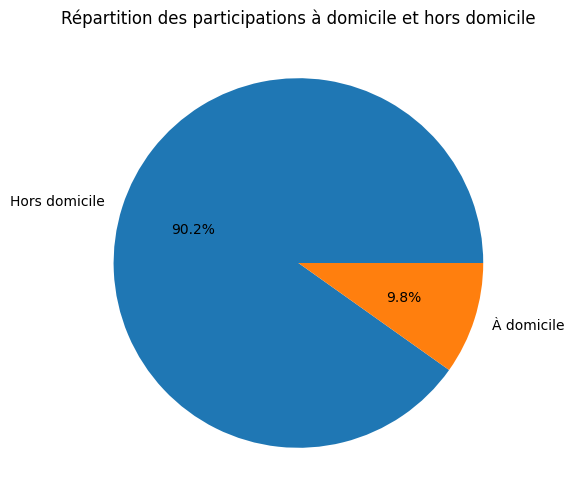

In [33]:
repartition_hotes = df_pays_hotes["Host"].value_counts()

repartition_hotes.plot.pie(
    autopct="%1.1f%%",
    labels=["Hors domicile", "À domicile"],
    title="Répartition des participations à domicile et hors domicile",
    figsize=(6, 6)
)

plt.ylabel("")
plt.show()

In [35]:
df_pays_hotes = df_pays_hotes.copy()

df_pays_hotes["Buts_par_match"] = (
    df_pays_hotes["Goals For"] / df_pays_hotes["Games Played"]
)

df_pays_hotes.groupby("Host")["Buts_par_match"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Host,,,,,,,,
False,211.0,1.48,0.76,0.00,1.00,1.33,2.00,4.17
True,23.0,1.81,0.85,0.33,1.23,1.83,2.14,3.75


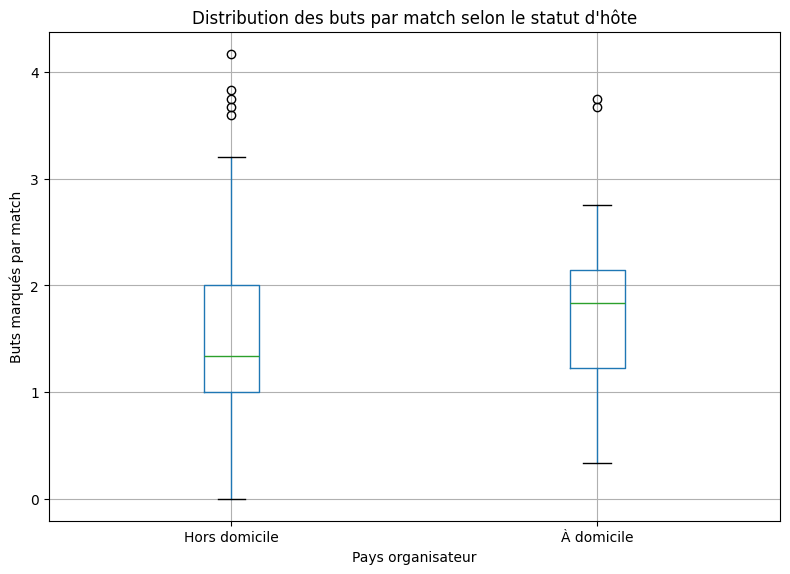

In [36]:
df_pays_hotes.boxplot(
    column="Buts_par_match",
    by="Host",
    figsize=(8, 6)
)

plt.title("Distribution des buts par match selon le statut d'hôte")
plt.suptitle("")
plt.xlabel("Pays organisateur")
plt.ylabel("Buts marqués par match")
plt.xticks([1, 2], ["Hors domicile", "À domicile"])
plt.tight_layout()
plt.show()

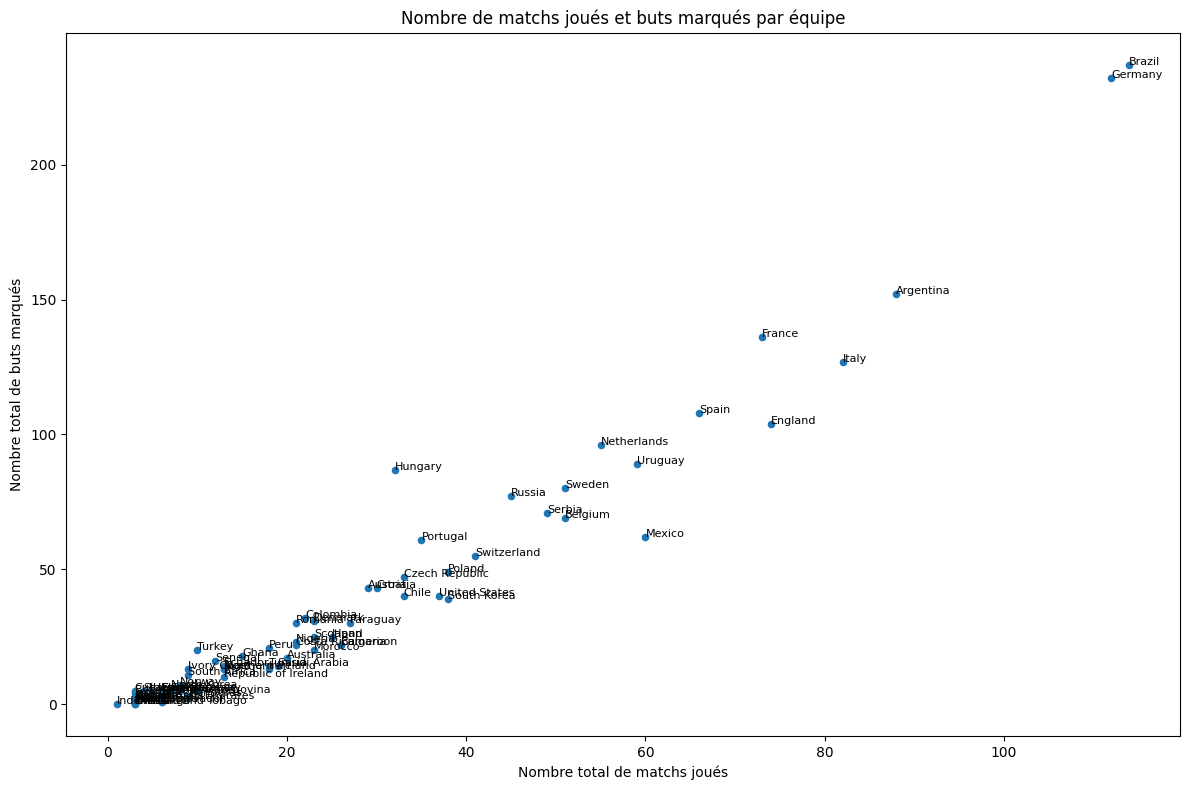

In [38]:
bilan_equipes = df_fifa.groupby("Team_Harmonized")[
    ["Games Played", "Goals For"]
].sum()

bilan_equipes.plot.scatter(
    x="Games Played",
    y="Goals For",
    figsize=(12, 8),
    title="Nombre de matchs joués et buts marqués par équipe"
)

for pays, ligne in bilan_equipes.iterrows():
    plt.annotate(
        pays,
        (ligne["Games Played"], ligne["Goals For"]),
        fontsize=8
    )

plt.xlabel("Nombre total de matchs joués")
plt.ylabel("Nombre total de buts marqués")
plt.tight_layout()
plt.show()

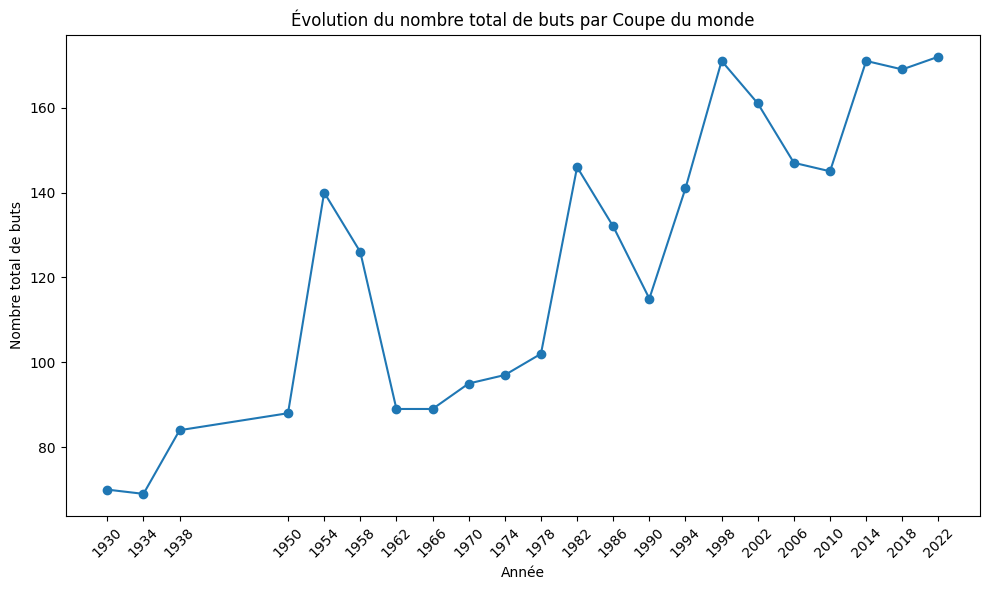

In [39]:
bilan_editions["Goals For"].plot(
    kind="line",
    marker="o",
    figsize=(10, 6),
    title="Évolution du nombre total de buts par Coupe du monde"
)

plt.xlabel("Année")
plt.ylabel("Nombre total de buts")
plt.xticks(bilan_editions.index, rotation=45)
plt.tight_layout()
plt.show()

In [52]:
import plotly.io as pio

fig = pio.read_json(file='file.json')
fig.show()
pio

top_buts = df_fifa.groupby("Team_Harmonized")["Goals For"].sum()
top_buts = top_buts.sort_values(ascending=False).head(10)
top_buts = top_buts.reset_index()

fig = pio.bar(
    top_buts,
    x="Team_Harmonized",
    y="Goals For",
    title="Top 10 des équipes par nombre de buts marqués",
    labels={
        "Team_Harmonized": "Équipe",
        "Goals For": "Buts marqués"
    }
)

fig.show()

ModuleNotFoundError: No module named 'plotly'

In [53]:
%pip install plotly

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   -------------------------------------- - 9.4/9.7 MB 58.8 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 43.1 MB/s  0:00:00

   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [54]:
import plotly.express as px

print("Plotly est installé correctement.")

Plotly est installé correctement.


In [57]:
top_buts = (
    df_fifa.groupby("Team_Harmonized")["Goals For"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

fig = px.bar(
    top_buts,
    x="Team_Harmonized",
    y="Goals For",
    title="Top 10 des équipes par nombre de buts marqués",
    labels={
        "Team_Harmonized": "Équipe",
        "Goals For": "Buts marqués"
    }
)

fig.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

In [56]:
%pip install "nbformat>=4.2.0"


   ----- ---------------------------------- 1/7 [fastjsonschema]
   ----------- ---------------------------- 2/7 [attrs]
   ----------------- ---------------------- 3/7 [referencing]
   ---------------------- ----------------- 4/7 [jsonschema-specifications]
   ---------------------------- ----------- 5/7 [jsonschema]
   ---------------------------- ----------- 5/7 [jsonschema]
   ---------------------------- ----------- 5/7 [jsonschema]
   ---------------------------------- ----- 6/7 [nbformat]
   ---------------------------------- ----- 6/7 [nbformat]
   ---------------------------------- ----- 6/7 [nbformat]
   ---------------------------------------- 7/7 [nbformat]

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [58]:
top_buts = (
    df_fifa.groupby("Team_Harmonized")["Goals For"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

fig = px.bar(
    top_buts,
    x="Team_Harmonized",
    y="Goals For",
    title="Top 10 des équipes par nombre de buts marqués",
    labels={
        "Team_Harmonized": "Équipe",
        "Goals For": "Buts marqués"
    }
)

fig.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

In [59]:
import sys
print(sys.executable)

%pip show nbformat

c:\Users\chris\AppData\Local\Programs\Python\Python310\python.exe
Name: nbformatNote: you may need to restart the kernel to use updated packages.

Version: 5.11.1
Summary: The Jupyter Notebook format
Home-page: https://jupyter.org
Author: 
Author-email: Jupyter Development Team <jupyter@googlegroups.com>
License: BSD 3-Clause License
        
        - Copyright (c) 2001-2015, IPython Development Team
        - Copyright (c) 2015-, Jupyter Development Team
        
        All rights reserved.
        
        Redistribution and use in source and binary forms, with or without
        modification, are permitted provided that the following conditions are met:
        
        1. Redistributions of source code must retain the above copyright notice, this
           list of conditions and the following disclaimer.
        
        2. Redistributions in binary form must reproduce the above copyright notice,
           this list of conditions and the following disclaimer in the documentatio